In [1]:
#1. 그래프 설정
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('실행 Python:', sys.executable)

실행 Python: /opt/anaconda3/bin/python3.13


In [2]:
########## 2. 실거래가·학교·학원 파일 읽기 ##########
root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data').exists()), None)
if root is None:
    raise FileNotFoundError('프로젝트 폴더 또는 src 폴더에서 실행하세요')
data = root / 'data'
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(data / '서울_아파트_매매_실거래가_2017-2026_통합.xlsx', sheet_name='아파트(매매) 실거래가', dtype=str)
school_raw = pd.read_csv(data / '04_교육' / '전국초중등학교위치표준데이터.csv', encoding='cp949', dtype=str)
academy_raw = pd.read_csv(data / '04_교육' / '학원교습소정보.csv', encoding='utf-8-sig', dtype=str, low_memory=False)
print(f'실거래가: {len(raw):,}행 / 학교: {len(school_raw):,}행 (전국) / 학원·교습소: {len(academy_raw):,}행 (서울)')

실거래가: 547,735행 / 학교: 12,004행 (전국) / 학원·교습소: 25,521행 (서울)


In [3]:
########## 3. 서울 아파트 매매만 남기고 ㎡당 가격 정리 ##########
df = raw.copy()
df.columns = df.columns.str.strip()
for col in df.columns:
    df[col] = df[col].astype('string').str.strip()

def numeric(series):
    return pd.to_numeric(series.str.replace(',', '', regex=False), errors='coerce').astype(float)

df['가격_만원'] = numeric(df['거래금액(만원)'])
df['면적_m2'] = numeric(df['전용면적(㎡)'])
df['계약년'] = numeric(df['계약년월'].str[:4])
df['자치구'] = df['시군구'].str.extract(r'^서울특별시\s+(\S+구)(?:\s|$)', expand=False)
df['법정동'] = df['시군구'].str.split().str[2]
cancelled = ~df['해제사유발생일'].fillna('').isin(['', '-', '0'])
seoul_apt = df['자치구'].notna() & df['주택유형'].eq('아파트').fillna(False)
valid = df['가격_만원'].gt(0) & df['면적_m2'].gt(0) & df['계약년'].notna()
keep = (seoul_apt & ~cancelled & valid).fillna(False)
df = df.loc[keep].copy()
df['m2당_만원'] = df['가격_만원'] / df['면적_m2']
df['log가격'] = np.log(df['m2당_만원'])
print(f"분석 거래: {len(df):,}건 / 자치구 {df['자치구'].nunique()}개 / 법정동 {df.groupby(['자치구', '법정동']).ngroups}개")

분석 거래: 530,129건 / 자치구 25개 / 법정동 338개


In [4]:
########## 4. 동별 학교 수·입시학원 수 만들기 ##########
school = school_raw[school_raw['소재지지번주소'].str.startswith('서울특별시', na=False) & school_raw['운영상태'].eq('운영')].copy()
school[['자치구', '법정동']] = school['소재지지번주소'].str.split(expand=True)[[1, 2]]
school_count = school.pivot_table(index=['자치구', '법정동'], columns='학교급구분', values='학교ID', aggfunc='count', fill_value=0)
school_count = school_count.rename(columns={'초등학교': '초등학교수', '중학교': '중학교수', '고등학교': '고등학교수'})

academy = academy_raw[academy_raw['분야명'].eq('입시.검정 및 보습')].copy()
academy['자치구'] = academy['행정구역명']
academy['법정동'] = academy['도로명상세주소'].str.extract(r'\(\s*([^,()\s]+(?:동|가))\s*[,)]', expand=False)
print(f"입시학원·교습소 {len(academy):,}곳 중 동 확인 {academy['법정동'].notna().mean():.1%}")
academy_count = academy.dropna(subset=['법정동']).groupby(['자치구', '법정동']).size().rename('학원수')

edu = school_count.join(academy_count, how='outer').fillna(0)
df = df.merge(edu, left_on=['자치구', '법정동'], right_index=True, how='left')
edu_cols = ['학원수', '초등학교수', '중학교수', '고등학교수']
df[edu_cols] = df[edu_cols].fillna(0)
display(df.drop_duplicates(['자치구', '법정동'])[edu_cols].describe().round(1))

입시학원·교습소 14,152곳 중 동 확인 97.6%


,학원수,초등학교수,중학교수,고등학교수
count,338.0000,338.0000,338.0000,338.0000
mean,40.6000,1.8000,1.1000,0.9000
std,95.2000,2.4000,1.6000,1.6000
min,0.0000,0.0000,0.0000,0.0000
25%,1.0000,0.0000,0.0000,0.0000
50%,9.0000,1.0000,0.0000,0.0000
75%,51.0000,3.0000,2.0000,1.0000
max,"1,228.0000",17.0000,9.0000,9.0000


In [5]:
########## 5. 학원 밀집 동과 학원가 정의 ##########
dong = df.groupby(['자치구', '법정동']).agg(거래량=('m2당_만원', 'size'), m2당중위가격_만원=('m2당_만원', 'median'), 학원수=('학원수', 'first'))
top10 = dong.sort_values('학원수', ascending=False).head(10)
display(top10)
df['학원가'] = df.set_index(['자치구', '법정동']).index.isin(top10.index).astype(int)
display(df.groupby('학원가').agg(거래량=('m2당_만원', 'size'), m2당중위가격_만원=('m2당_만원', 'median')).rename(index={0: '그 외', 1: '학원가'}))

거래량  m2당중위가격_만원        학원수
자치구 법정동                               
강남구 대치동    3820  2,496.6762 1,228.0000
양천구 목동     7498  1,449.1046   729.0000
    신정동   10262  1,171.2499   534.0000
노원구 중계동   10743    840.5216   402.0000
강동구 명일동    3519  1,301.5991   268.0000
서초구 반포동    4618  3,160.9863   229.0000
    방배동    4061  1,510.8276   226.0000
강서구 내발산동   2903  1,043.3860   220.0000
노원구 상계동   19024    825.7197   210.0000
서초구 서초동    6857  1,573.4066   198.0000

,거래량,m2당중위가격_만원
학원가,,
그 외,456824,"1,058.4677"
학원가,73305,"1,093.4343"


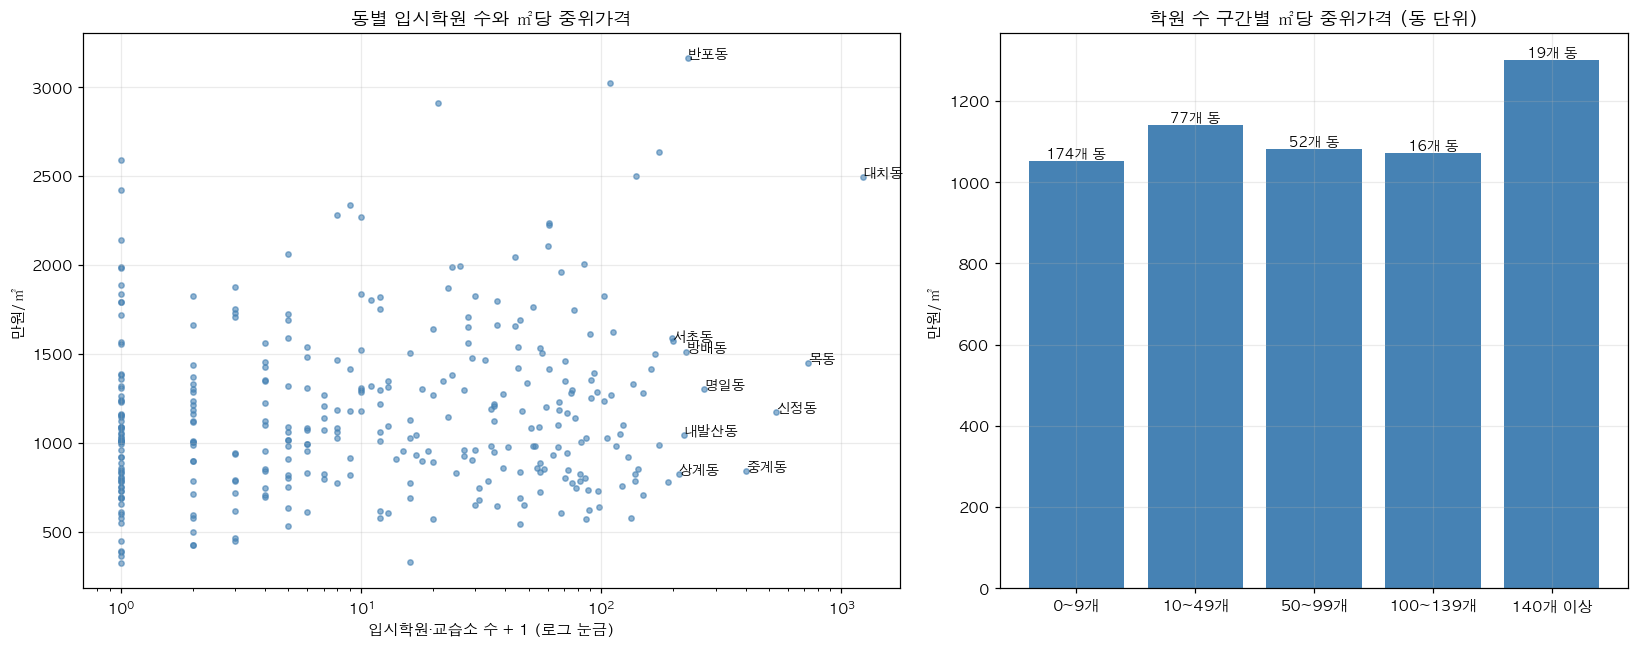

,log가격,학원수,초등학교수,중학교수,고등학교수
log가격,1.0000,0.0870,-0.2070,-0.1710,-0.1040


In [6]:
########## 6. 학원 수와 ㎡당 가격 ##########
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.3, 1]})
axes[0].scatter(dong['학원수'] + 1, dong['m2당중위가격_만원'], s=12, color='steelblue', alpha=0.6)
axes[0].set_xscale('log')
for (gu, d), row in top10.iterrows():
    axes[0].annotate(d, (row['학원수'] + 1, row['m2당중위가격_만원']), fontsize=9)
axes[0].set(title='동별 입시학원 수와 ㎡당 중위가격', xlabel='입시학원·교습소 수 + 1 (로그 눈금)', ylabel='만원/㎡')

bins = pd.cut(dong['학원수'], bins=[-1, 9, 49, 99, 139, np.inf], labels=['0~9개', '10~49개', '50~99개', '100~139개', '140개 이상'])
by_bin = dong.groupby(bins, observed=True)['m2당중위가격_만원'].agg(['size', 'median'])
axes[1].bar(by_bin.index.astype(str), by_bin['median'], color='steelblue')
for x, (n, v) in enumerate(zip(by_bin['size'], by_bin['median'])):
    axes[1].text(x, v, f'{n}개 동', ha='center', va='bottom', fontsize=9)
axes[1].set(title='학원 수 구간별 ㎡당 중위가격 (동 단위)', ylabel='만원/㎡')
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(df[['log가격', '학원수', '초등학교수', '중학교수', '고등학교수']].corr().round(3).iloc[[0]])

In [7]:
########## 7. 학습·평가 데이터 나누기 ##########
df['log학원수'] = np.log1p(df['학원수'])
df['동ID'] = pd.factorize(df['자치구'] + ' ' + df['법정동'])[0]
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f'학습: {len(train):,}건 / 평가: {len(test):,}건')

학습: 424,103건 / 평가: 106,026건


In [8]:
########## 8. 다중선형회귀 - 학원 수·학교 수 ##########
base = 'C(자치구) + C(계약년)'
ols = smf.ols(f'log가격 ~ {base} + log학원수 + 초등학교수 + 중학교수 + 고등학교수', data=train).fit(cov_type='cluster', cov_kwds={'groups': train['동ID']})
names = ['log학원수', '초등학교수', '중학교수', '고등학교수']
ols_result = pd.DataFrame({'계수': ols.params[names], '가격변화_%': (np.exp(ols.params[names]) - 1) * 100, 'p값': ols.pvalues[names]})
print(f"학원 수가 2배인 동: ㎡당 가격 {(2 ** ols.params['log학원수'] - 1) * 100:+.2f}%")
print('학교 수: 학교 1개 많을 때 가격 변화 %')
display(ols_result)
print(f'학습 데이터 R²: {ols.rsquared:.3f}')

학원 수가 2배인 동: ㎡당 가격 +2.11%
학교 수: 학교 1개 많을 때 가격 변화 %


,계수,가격변화_%,p값
log학원수,0.0301,3.0590,0.0502
초등학교수,-0.0018,-0.1837,0.8286
중학교수,-0.0218,-2.1556,0.1567
고등학교수,0.0275,2.7867,0.0108


학습 데이터 R²: 0.600


In [9]:
########## 9. Random Forest ##########
features = ['계약년', '자치구코드', '학원수', '초등학교수', '중학교수', '고등학교수']
codes = {g: i for i, g in enumerate(sorted(df['자치구'].unique()))}
X_train = train.assign(자치구코드=train['자치구'].map(codes))[features].astype(float)
X_test = test.assign(자치구코드=test['자치구'].map(codes))[features].astype(float)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, train['log가격'])
print('학습 완료: 나무', rf.n_estimators, '개')

학습 완료: 나무 200 개


In [10]:
########## 10. 두 모델 성능 비교 ##########
true = test['m2당_만원']
pred = {'다중선형회귀': np.exp(ols.predict(test)), 'Random Forest': np.exp(rf.predict(X_test))}
score = pd.DataFrame({
    name: {'MAE_만원/㎡': mean_absolute_error(true, p), 'RMSE_만원/㎡': mean_squared_error(true, p) ** 0.5, 'R²': r2_score(true, p)}
    for name, p in pred.items()
}).T
display(score.round(3))

,MAE_만원/㎡,RMSE_만원/㎡,R²
다중선형회귀,329.6220,503.3160,0.5460
Random Forest,261.9280,397.6970,0.7170


,중요도,표준편차
자치구코드,0.9064,0.0075
계약년,0.4236,0.0068
학원수,0.3072,0.0030
중학교수,0.1579,0.0014
초등학교수,0.1205,0.0020
고등학교수,0.0689,0.0012


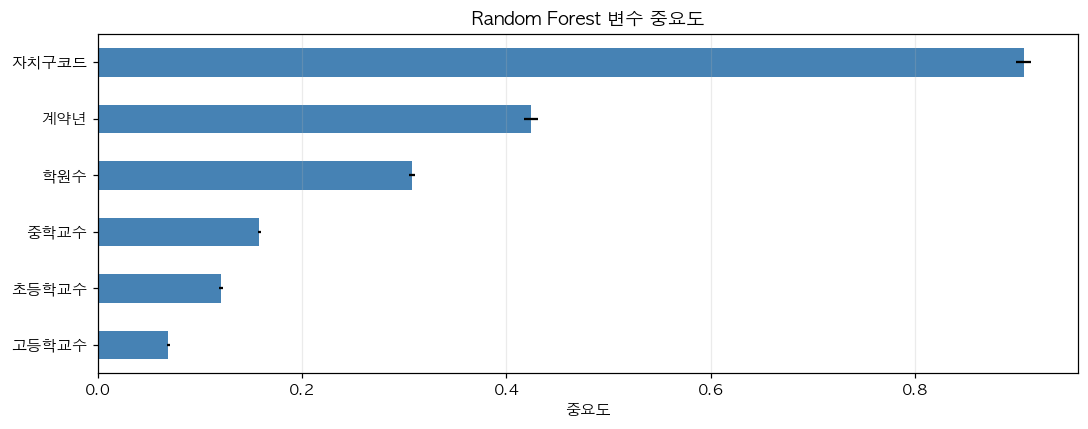

In [11]:
########## 11. 변수 중요도 (Permutation Importance) ##########
sample = X_test.sample(min(20000, len(X_test)), random_state=42)
pi = permutation_importance(rf, sample, test.loc[sample.index, 'log가격'], n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({'중요도': pi.importances_mean, '표준편차': pi.importances_std}, index=features).sort_values('중요도', ascending=False)
display(importance)
ax = importance['중요도'].sort_values().plot.barh(figsize=(10, 4), color='steelblue', xerr=importance['표준편차'])
ax.set(title='Random Forest 변수 중요도', xlabel='중요도', ylabel='')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

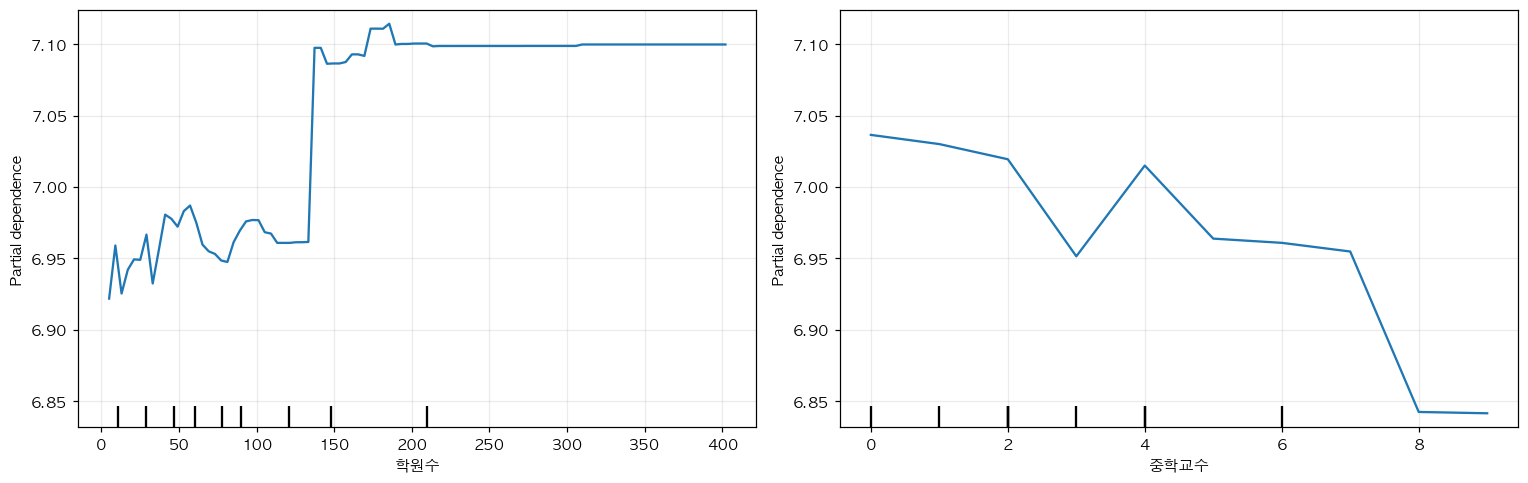

In [12]:
########## 12. 학원 수에 따른 예측가격 변화 ##########
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
PartialDependenceDisplay.from_estimator(rf, sample, ['학원수', '중학교수'], ax=axes)
for ax in fig.axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
########## 13. 대형 학원가 변수 만들기 (학원 수 140개 이상) ##########
THRESHOLD = 140
df['is_major_academy'] = (df['학원수'] >= THRESHOLD).astype(int)
dong = dong.assign(is_major_academy=(dong['학원수'] >= THRESHOLD).astype(int))
major = dong[dong['is_major_academy'] == 1].sort_values('학원수', ascending=False)
print(f'학원 수 {THRESHOLD}개 이상: {len(major)}개 동 / 그 외 {len(dong) - len(major)}개 동')
display(major[['학원수', '거래량', 'm2당중위가격_만원']])

학원 수 140개 이상: 19개 동 / 그 외 319개 동


학원수    거래량  m2당중위가격_만원
자치구 법정동                               
강남구 대치동  1,228.0000   3820  2,496.6762
양천구 목동     729.0000   7498  1,449.1046
    신정동    534.0000  10262  1,171.2499
노원구 중계동    402.0000  10743    840.5216
강동구 명일동    268.0000   3519  1,301.5991
서초구 반포동    229.0000   4618  3,160.9863
    방배동    226.0000   4061  1,510.8276
강서구 내발산동   220.0000   2903  1,043.3860
노원구 상계동    210.0000  19024    825.7197
서초구 서초동    198.0000   6857  1,573.4066
송파구 방이동    197.0000   2258  1,589.1701
강서구 화곡동    189.0000   6638    780.6678
관악구 봉천동    173.0000   9881    984.1004
서초구 잠원동    173.0000   3737  2,635.5748
강남구 신사동    167.0000    377  1,500.0000
광진구 구의동    161.0000   2234  1,413.1779
강서구 마곡동    148.0000   3033  1,276.6493
양천구 신월동    148.0000   6095    706.0185
도봉구 창동     141.0000   8614    852.0865

In [14]:
########## 14. 두 집단 기초 통계량 ##########
group_name = {0: f'{THRESHOLD}개 미만', 1: f'{THRESHOLD}개 이상'}
print('거래 단위 ㎡당 가격 (만원/㎡)')
display(df.groupby('is_major_academy')['m2당_만원'].agg(['count', 'mean', 'median', 'std']).rename(index=group_name))
print('동 단위 ㎡당 중위가격 (만원/㎡)')
display(dong.groupby('is_major_academy')['m2당중위가격_만원'].agg(['count', 'mean', 'median', 'std']).rename(index=group_name))

거래 단위 ㎡당 가격 (만원/㎡)


,count,mean,median,std
is_major_academy,,,,
140개 미만,413957,"1,247.3921","1,065.1372",703.4695
140개 이상,116172,"1,319.3830","1,048.5391",871.2465


동 단위 ㎡당 중위가격 (만원/㎡)


,count,mean,median,std
is_major_academy,,,,
140개 미만,319,"1,150.6716","1,070.5789",452.6788
140개 이상,19,"1,426.8907","1,301.5991",670.5295


In [15]:
########## 15. 두 집단 차이 검정 (동 단위) ##########
high = dong.loc[dong['is_major_academy'] == 1, 'm2당중위가격_만원']
low_ = dong.loc[dong['is_major_academy'] == 0, 'm2당중위가격_만원']
t_stat, t_p = stats.ttest_ind(high, low_, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(high, low_, alternative='two-sided')
print(f'Welch t-검정: t = {t_stat:.3f}, p = {t_p:.4f}')
print(f'Mann-Whitney U 검정: U = {u_stat:,.0f}, p = {u_p:.4f}')

Welch t-검정: t = 1.772, p = 0.0925
Mann-Whitney U 검정: U = 3,764, p = 0.0765


In [16]:
########## 16. 다중선형회귀 - 대형 학원가 프리미엄 ##########
ols_major = smf.ols('np.log(m2당_만원) ~ is_major_academy + C(자치구) + C(계약년)', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df['동ID']})
print(ols_major.summary())
coef = ols_major.params['is_major_academy']
ci_low, ci_high = ols_major.conf_int().loc['is_major_academy']
premium_major = (np.exp(coef) - 1) * 100
print(f'\n프리미엄: {premium_major:+.1f}% (exp 방식) / {coef * 100:+.1f}% (100×계수 방식)')
print(f'95% 신뢰구간: {(np.exp(ci_low) - 1) * 100:+.1f}% ~ {(np.exp(ci_high) - 1) * 100:+.1f}% / p값 {ols_major.pvalues["is_major_academy"]:.4f}')

                            OLS Regression Results                            
Dep. Variable:         np.log(m2당_만원)   R-squared:                       0.592
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     314.5
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          1.47e-233
Time:                        14:38:47   Log-Likelihood:            -1.6097e+05
No. Observations:              530129   AIC:                         3.220e+05
Df Residuals:                  530094   BIC:                         3.224e+05
Df Model:                          34                                         
Covariance Type:              cluster                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            7.2722      0.058  

In [17]:
########## 17. 기준을 바꿔도 프리미엄이 유지되는지 확인 ##########
rows = []
top10_mask = df.set_index(['자치구', '법정동']).index.isin(top10.index).astype(int)
for label, flag in [('100개 이상', (df['학원수'] >= 100).astype(int)),
                    ('140개 이상', df['is_major_academy']),
                    ('200개 이상', (df['학원수'] >= 200).astype(int)),
                    ('상위 10개 동', top10_mask)]:
    m = smf.ols('np.log(m2당_만원) ~ flag + C(자치구) + C(계약년)', data=df.assign(flag=flag)).fit(
        cov_type='cluster', cov_kwds={'groups': df['동ID']})
    lo, hi = m.conf_int().loc['flag']
    rows.append({'기준': label, '동 수': df.loc[flag == 1, '동ID'].nunique(),
                 '프리미엄_%': (np.exp(m.params['flag']) - 1) * 100,
                 '95%CI_하한': (np.exp(lo) - 1) * 100, '95%CI_상한': (np.exp(hi) - 1) * 100, 'p값': m.pvalues['flag']})
sensitivity = pd.DataFrame(rows).set_index('기준')
display(sensitivity.round(4))

,동 수,프리미엄_%,95%CI_하한,95%CI_상한,p값
기준,,,,,
100개 이상,35,11.8922,3.9404,20.4523,0.0028
140개 이상,19,9.2010,0.5596,18.5851,0.0364
200개 이상,9,16.5992,1.0410,34.5531,0.0356
상위 10개 동,10,11.8193,-3.1974,29.1655,0.1289


,count,mean,median
is_major_academy,,,
140개 미만,319,-6.8500,-6.6594
140개 이상,19,7.1591,6.1164


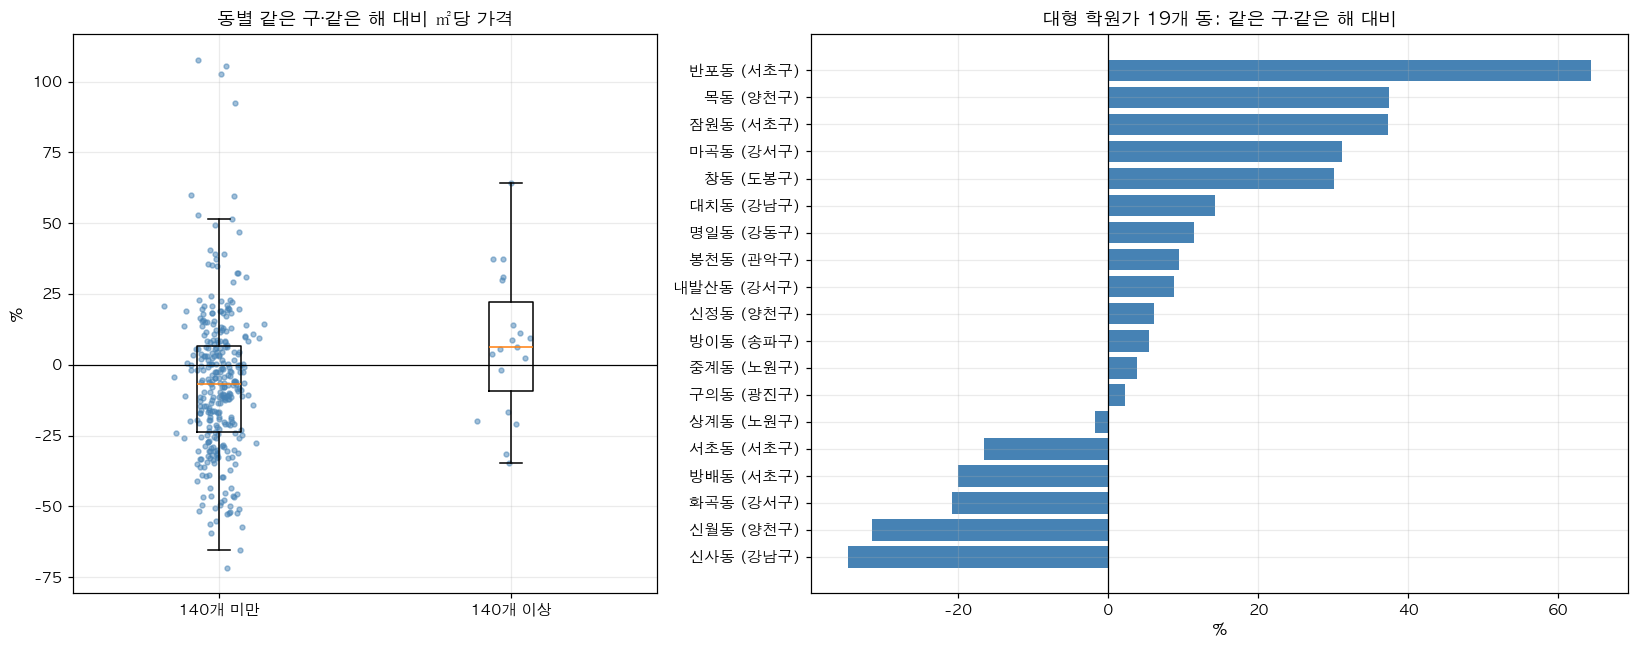

In [18]:
########## 18. 같은 구·같은 해 대비 가격 비교 ##########
df['구연도대비_%'] = (df['m2당_만원'] / df.groupby(['자치구', '계약년'])['m2당_만원'].transform('median') - 1) * 100
rel = df.groupby(['자치구', '법정동']).agg(구연도대비_pct=('구연도대비_%', 'median'), is_major_academy=('is_major_academy', 'first'))
display(rel.groupby('is_major_academy')['구연도대비_pct'].agg(['count', 'mean', 'median']).rename(index=group_name))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.4]})
data = [rel.loc[rel['is_major_academy'] == g, '구연도대비_pct'] for g in [0, 1]]
axes[0].boxplot(data, showfliers=False)
for k, values in enumerate(data, start=1):
    axes[0].scatter(np.random.default_rng(0).normal(k, 0.05, len(values)), values, s=10, color='steelblue', alpha=0.5)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_xticks([1, 2], [group_name[0], group_name[1]])
axes[0].set(title='동별 같은 구·같은 해 대비 ㎡당 가격', ylabel='%')
major_rel = rel.loc[rel['is_major_academy'] == 1, '구연도대비_pct'].sort_values()
axes[1].barh([f'{d} ({g})' for g, d in major_rel.index], major_rel, color='steelblue')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title=f'대형 학원가 {len(major_rel)}개 동: 같은 구·같은 해 대비', xlabel='%')
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [19]:
########## 19. 결과를 숫자로 확인 ##########
print(f"학원 수 2배: ㎡당 가격 {(2 ** ols.params['log학원수'] - 1) * 100:+.2f}% (p값 {ols.pvalues['log학원수']:.4f})")
edu_rank = importance.index.get_indexer(['학원수']) + 1
print(f"RF 중요도 순위: {' > '.join(importance.index)} (학원수 {edu_rank[0]}위)")
best = score['R²'].idxmax()
print(f"평가 R²가 높은 모델: {best} ({score.loc[best, 'R²']:.3f}, MAE {score.loc[best, 'MAE_만원/㎡']:.0f}만원/㎡)")
print(f"대형 학원가({THRESHOLD}개 이상, {len(major)}개 동) 프리미엄: {premium_major:+.1f}% (p값 {ols_major.pvalues['is_major_academy']:.4f})")
print(f"동 단위 검정: Welch t p = {t_p:.4f} / Mann-Whitney U p = {u_p:.4f}")
print('기준별 프리미엄:', ', '.join(f"{k} {v:+.1f}%" for k, v in sensitivity['프리미엄_%'].items()))
print('학원 자료는 현재(2026) 등록 기준이라 과거 거래 시점의 학원 수와 다를 수 있습니다.')
print('학원 수는 동의 크기·상권과도 관련되어 있어 학군 효과만 따로 떼어낸 값은 아닙니다.')

학원 수 2배: ㎡당 가격 +2.11% (p값 0.0502)
RF 중요도 순위: 자치구코드 > 계약년 > 학원수 > 중학교수 > 초등학교수 > 고등학교수 (학원수 3위)
평가 R²가 높은 모델: Random Forest (0.717, MAE 262만원/㎡)
대형 학원가(140개 이상, 19개 동) 프리미엄: +9.2% (p값 0.0364)
동 단위 검정: Welch t p = 0.0925 / Mann-Whitney U p = 0.0765
기준별 프리미엄: 100개 이상 +11.9%, 140개 이상 +9.2%, 200개 이상 +16.6%, 상위 10개 동 +11.8%
학원 자료는 현재(2026) 등록 기준이라 과거 거래 시점의 학원 수와 다를 수 있습니다.
학원 수는 동의 크기·상권과도 관련되어 있어 학군 효과만 따로 떼어낸 값은 아닙니다.
